# Исследовательский анализ жалоб CFPB

## Ключевой вопрос

В чем причина изменения количества жалоб в первом квартале 2025 года по сравнению с первым кварталом 2024 года?

## Исследовательские вопросы

1. Как изменилось количество жалоб между первым кварталом 2024 и первым кварталом 2025?
2. Как различается соотношение продуктов?
3. Как различается соотношение по проблемам?
4. Какова доля своевременных ответов?
5. Какие компании и регионы чаще всего фигурируют в жалобах?
6. Как распределено время передачи жалобы компании?
7. **Чем объясняется необычный объём жалоб в январе 2025 года?**

#### Ограничения

База CFPB не является полностью репрезентативной выборкой
всех клиентов финансовых организаций.

Количество жалоб нельзя напрямую интерпретировать как качество
компании или продукта без информации о размере клиентской базы
и рыночной доле.

In [50]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [51]:
CURRENT_DIR=Path.cwd()
PROJECT_ROOT=(
    CURRENT_DIR.parent
    if CURRENT_DIR.name=="notebooks"
    else CURRENT_DIR
)
DATA_PATH = (PROJECT_ROOT /"data"/"processed"/"complaints_clean.pkl")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Файл не найден: {DATA_PATH}")
FIGURES_DIR = (PROJECT_ROOT/"reports"/"figures")
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)
df=pd.read_pickle(DATA_PATH)
print("Размер таблицы:", df.shape)  # ожидаемый результат: (141822, 21)

Размер таблицы: (141822, 21)


#### Подключение DuckDB

Будем работать с SQL-запросами для агрегации данных

In [52]:
sql_df = df.drop(
    columns=["year_month"],
    errors="ignore"
).copy()
connection = duckdb.connect(database=":memory:")
connection.register("complaints", sql_df)

## Аналитические вопросы

#### Как изменилось количество жалоб между первым кварталом 2024 и первым кварталом 2025?

Сначала сравним кварталы целиком, чтобы увидеть картину в общем

In [53]:
yearly_counts=connection.sql(
    """
    SELECT year,
        COUNT(*) AS complaint_count
    FROM complaints
    GROUP BY year
    ORDER BY year
    """
).df()
yearly_counts

,year,complaint_count
0,2024,32489
1,2025,109333


Наблюдается значительное преобладание 2025 года в количестве жалоб.

Для точности, рассчитаем абсолютное и относительное изменение

In [54]:
counts=yearly_counts.set_index("year")["complaint_count"]
counts_2024=counts.loc[2024]
counts_2025=counts.loc[2025]
absolute_change=counts_2025 - counts_2024
percent_change=absolute_change/counts_2024 * 100
print("Абсолютное изменение:", absolute_change)
print(f"Относительное изменение:{round(percent_change, 2)} %")

Абсолютное изменение: 76844
Изменение:236.52 %


Для формирования наиболее ясного понимания, рассмотрим динамику по месяцам внутри кварталов

Для большей наглядности визуализируем ее с помощью графика

In [55]:
yearly_counts=connection.sql(
    """
    SELECT year,
        month,
        COUNT(*) AS complaint_count
    FROM complaints
    GROUP BY year, month
    ORDER BY year, month
    """
).df()
yearly_counts

,year,month,complaint_count
0,2024,1,10565
1,2024,2,10321
2,2024,3,11603
3,2025,1,77183
4,2025,2,17793
5,2025,3,14357


Рассмотрим динамику по месяцам, чтобы понять, как росли обращения

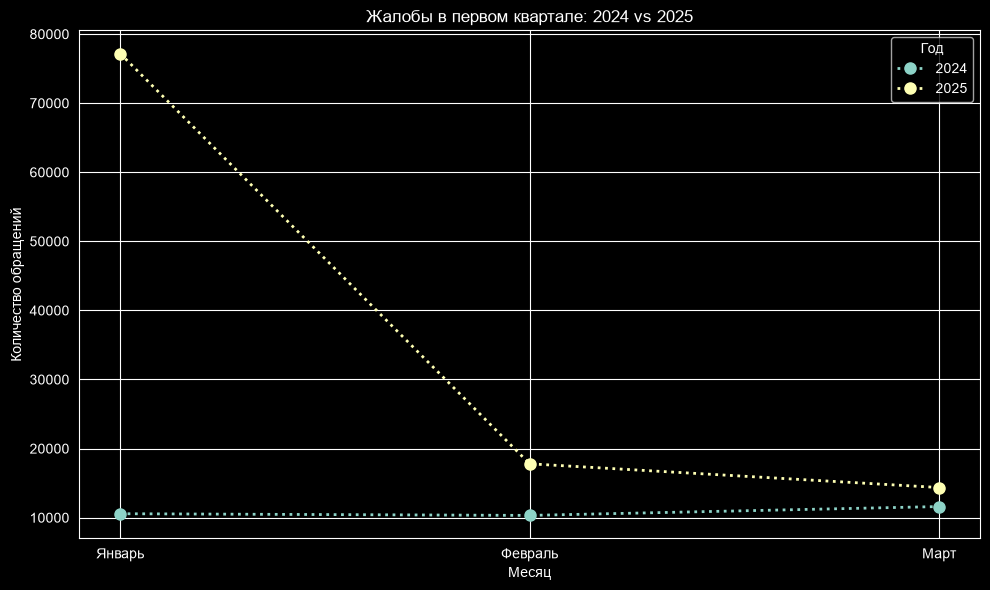

In [104]:
fig, ax=plt.subplots(figsize=(10, 6))
for year, grp in yearly_counts.groupby("year"):
    grp=grp.sort_values("month")
    ax.plot(
        grp["month"],
        grp["complaint_count"],
        marker="o",
        linewidth=2,
        markersize=8,
        linestyle=":",
        label=str(year)
    )
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["Январь", "Февраль", "Март"])
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество обращений")
ax.set_title("Жалобы в первом квартале: 2024 vs 2025")
ax.legend(title="Год")
plt.tight_layout()
plt.show()


Наблюдения:
- В январе 2025 года количество обращений было аномальным, оно значительно превышало как показатели за январь прошлого года, так и количество обращений за следующие месяцы квартала
- Количество обращений по каждому месяцу первого квартала 2025 года повышает аналогические значения для 2024 года
- Среди месяцев первого квартала 2024 года значения почти не изменяются

#### Как различается соотношение продуктов?

In [57]:
monthly_counts=connection.sql(
    """
    SELECT year,
        product,
        COUNT(*) AS complaint_count,
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY year) AS complaint_percentage
    FROM complaints
    GROUP BY year, product
    ORDER BY year
    """
).df()
monthly_counts

,year,product,complaint_count,complaint_percentage
0,2024,Credit card,16318,50.226230
1,2024,Checking or savings account,12122,37.311090
2,2024,"Money transfer, virtual currency, or money ser...",4049,12.462680
3,2025,"Money transfer, virtual currency, or money ser...",58903,53.874859
4,2025,Checking or savings account,28889,26.422946
5,2025,Credit card,21541,19.702194


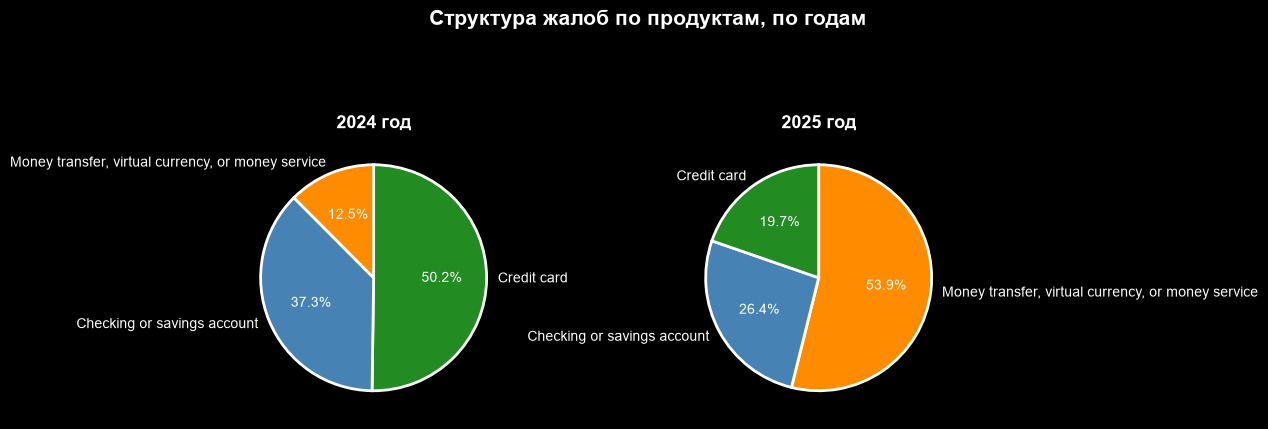

In [107]:
years=sorted(monthly_counts["year"].unique())
color_map={
    "Credit card": "#228B22",
    "Checking or savings account": "#4682B4",
    "Money transfer, virtual currency, or money service": "#FF8C00"}
fig, axes = plt.subplots(1, len(years), figsize=(6 * len(years), 5))

for ax, y in zip(axes, years):
    sub = (monthly_counts[monthly_counts["year"] == y].sort_values("complaint_count", ascending=False))
    pie_colors=[color_map[x] for x in sub["product"]]
    ax.pie(
        sub["complaint_count"],
        labels=sub["product"],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        colors=pie_colors,
        wedgeprops=dict(edgecolor="white", linewidth=2),
    )
    ax.set_title(f"{y} год", fontsize=13, fontweight="bold")
fig.suptitle("Структура жалоб по продуктам, по годам", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Наблюдения**

- Значительно выросла доля жалоб на денежные переводы, виртуальную валюту или денежные сервисы(`Money transfer, virtual currency, or money service`), рост составил 41.4 процентных пунктов
- Значительно сократилась доля жалоб, связанных с кредитными картами(`Credit card`): доля уменьшилась с 50.2% до 19.4% т.е. на 30.8 процентных пунктов
- Сокращение жалоб по поводу счета(`Checking or savings account`) составляет 10.9 процентных пунктов

**Интерпретация**

Структура жалоб сильно изменилась, но стоит учитывать, что абсолютное количество жалоб выросло по всем трём продуктам. Особенно требует рассмотрения категория денежных переводов, поскольку она выросла настолько сильнее других анализируемых продуктов, что заняла большую часть всей выборки7 Именно из-за такого роста `Money transfer, virtual currency, or money service` доли жалоб по кредитным картам и банковским счетам сократились, при росте абсолютного значения

**Гипотеза**

Резкий рост категории денежных переводов, виртуальной валюты и денежных сервисов (`Money transfer, virtual currency, or money service`) в первого квартале 2025 года распределен неравномерно и сконцентрирован в определенной подкатегории жалоб и компаний. Рассмотрим соотношение `issue`, вклад отдельных компаний и помесячную динамику жалоб.

#### Как различается соотношение по проблемам?

In [59]:
issue_structure = connection.sql(
    """
    WITH issue_counts AS (
        SELECT year,
            product,
            issue,
            COUNT(*) AS issue_count
        FROM complaints
        WHERE issue IS NOT NULL
        GROUP BY year, product, issue
    )
    SELECT year,
        product,
        issue,
        issue_count,
        ROUND(100.0 * issue_count/SUM(issue_count) OVER (PARTITION BY year, product), 2) AS issue_percent
    FROM issue_counts
    ORDER BY product,
        year,
        issue_count DESC
    """
).df()

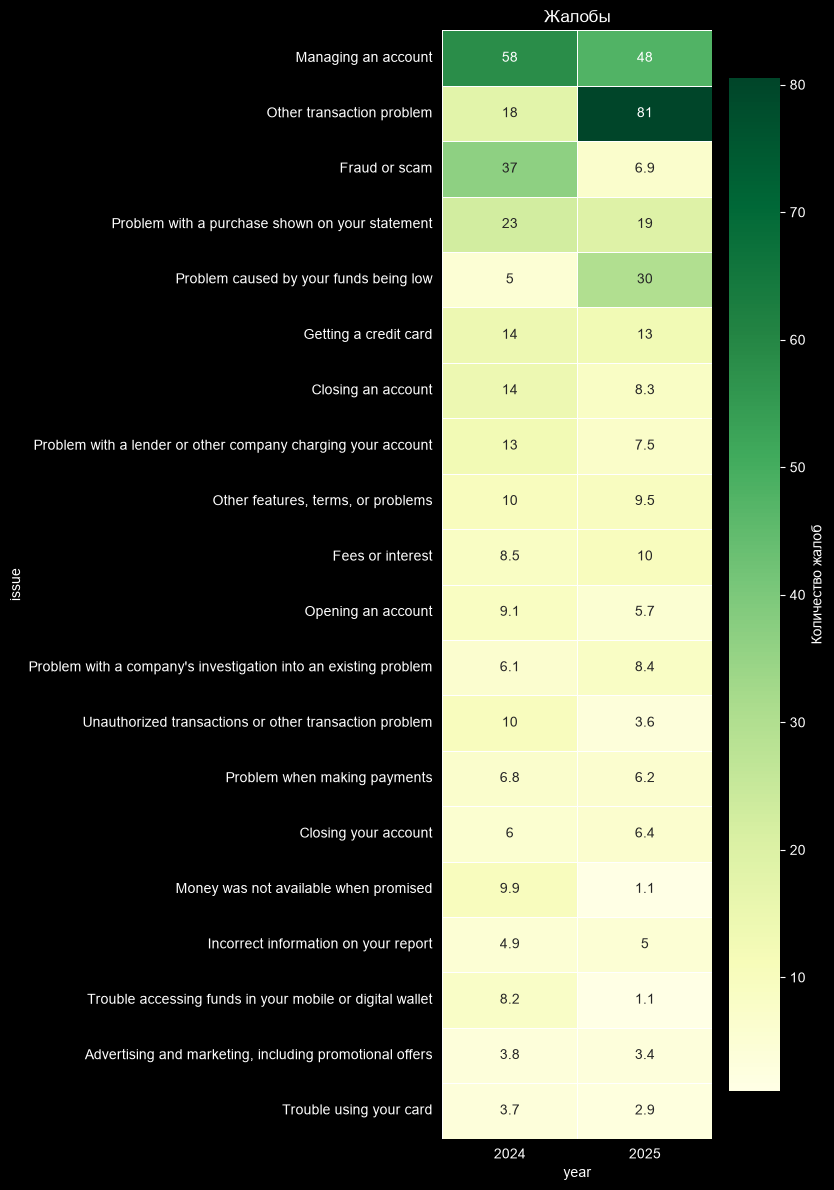

In [66]:
pivot=(issue_structure.pivot_table(index="issue", columns="year",
                 values="issue_percent", fill_value=0))
top_issues = pivot.sum(axis=1).nlargest(20).index
pivot = pivot.loc[top_issues]
fig, ax = plt.subplots(figsize=(8, 12))
sns.heatmap(
    pivot, annot=True, cmap="YlGn",
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Количество жалоб"}, ax=ax)
ax.set_title("Жалобы")
plt.tight_layout()
plt.show()

**Наблюдение**

Значительно выросла категория `Other transaction problem`: с 18% до 81% т.е. рост составил 63 процентных пункта

**Описание категории Other transaction problem**

- Несанкционированная транзакция

     Клиент утверждает, что не совершал или не разрешал перевод
- Проблема с отменой транзакции

     Перевод не удалось отменить либо отмена была обработана неправильно;
- Проблема с возвратом денег

     Возврат не поступил, задержался или был обработан некорректно.

Посмотрим, можем ли мы оценить структуру `sub_issue`

In [126]:
sub_issue_counts=connection.sql(
    """
    SELECT issue,
        sub_issue
    FROM complaints
    WHERE issue='Other transaction problem'
    GROUP BY issue,
        sub_issue
"""
)
sub_issue_counts

┌───────────────────────────┬───────────┐
│           issue           │ sub_issue │
│          varchar          │  varchar  │
├───────────────────────────┼───────────┤
│ Other transaction problem │ NULL      │
└───────────────────────────┴───────────┘

**Наблюдение и интерпретация**

Подпроблем не наблюдалось

**Интерпретация**

К сожалению, из-за этого не получится рассмотреть структуру подпроблем в интересующей нас категории `Other transaction problem`

Рост Other transaction problem в 2025 году распределён неравномерно и сконцентрирован в определённом месяце и ограниченном количестве компаний.

**Гипотеза**

Рост Other transaction problem в 2025 году распределён неравномерно и сконцентрирован в определённом месяце и ограниченном количестве компаний.

In [129]:
other_transaction_monthly = connection.sql(
    """
    SELECT
        year,
        month,
        COUNT(*) AS complaint_count

    FROM complaints

    WHERE issue = 'Other transaction problem'

    GROUP BY year, month

    ORDER BY year, month
    """
).df()

other_transaction_monthly

,year,month,complaint_count
0,2024,1,226
1,2024,2,227
2,2024,3,276
3,2025,1,42521
4,2025,2,3720
5,2025,3,1189


**Наблюдение**

Количество жалоб Other transaction problem действительно не распределено равномерно и большинство сообщений приходится на январь 2025 года

Оценим ежедневную динамику внутри пикового месяца

In [130]:
other_transaction_daily = connection.sql(
    """
    SELECT
        CAST(date_received AS DATE) AS received_date,
        COUNT(*) AS complaint_count

    FROM complaints

    WHERE issue = 'Other transaction problem'
      AND date_received >= '2025-01-01'
      AND date_received < '2025-02-01'

    GROUP BY received_date

    ORDER BY received_date
    """
).df()

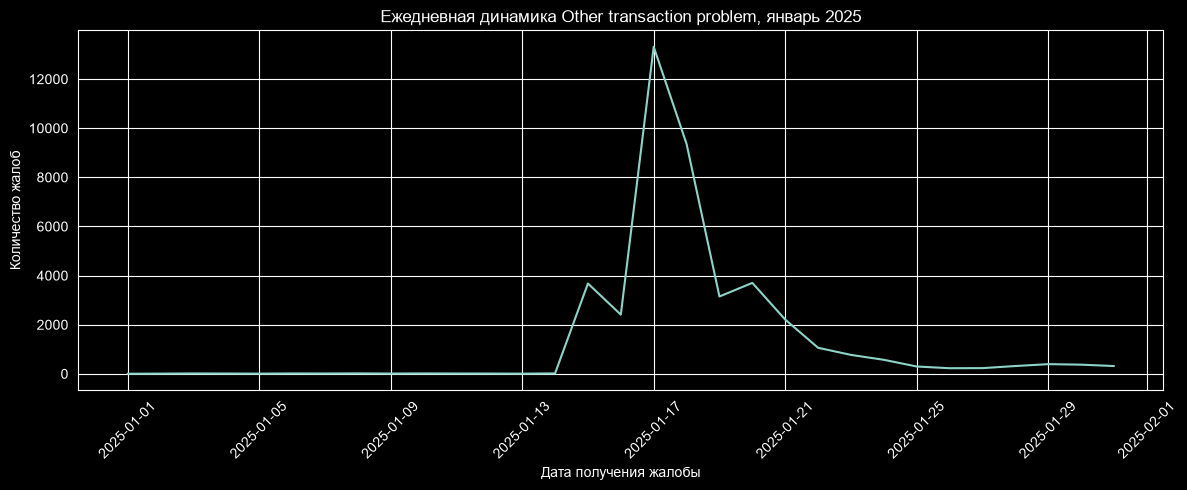

In [132]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=other_transaction_daily,
    x="received_date",
    y="complaint_count"
)
plt.title('Ежедневная динамика "Other transaction problem" за январь 2025')
plt.xlabel("Дата получения жалобы")
plt.ylabel("Количество жалоб")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Наблюдение**

Количество обращений за 17 января 2025 года является максимальным в рамках января и составляет свыше 12 тысяч обращений

#### Какова доля своевременных ответов?

In [61]:
answers_timely= connection.sql(
    """
     SELECT year,
        month,
        ROUND(COUNT(*) FILTER (WHERE timely_response) * 100.0 / COUNT(*), 2) AS percent_timely_answer
    FROM complaints
    GROUP BY year, month
    ORDER BY year, month
    """
).df()
answers_timely

,year,month,percent_timely_answer
0,2024,1,99.46
1,2024,2,99.36
2,2024,3,99.07
3,2025,1,99.80
4,2025,2,99.41
5,2025,3,99.37


**Наблюдение**

- В каждом месяце доля не пришедших вовремя ответов является настолько маленькой, что ей можно пренебречь
- Разброс процента вовремя пришедших ответов крайне мал: минимум в марте 2024 года-99.07% и максимум в январе 2025 года-99.80% т.е. разница составляет 0.73 п.п.


#### Какие компании и регионы выделяются в данных?

In [62]:
company_counts=connection.sql (
    """
    SELECT company,
        year,
        COUNT(*) AS total_complaint
    FROM complaints
    GROUP BY company, year
    ORDER BY total_complaint DESC
    """
).df()
company_counts

,company,year,total_complaint
0,"Block, Inc.",2025,36469
1,"Early Warning Services, LLC",2025,18351
2,NAVY FEDERAL CREDIT UNION,2025,8894
3,CAPITAL ONE FINANCIAL CORPORATION,2025,7859
4,JPMORGAN CHASE & CO.,2025,4308
...,...,...,...
966,Escrow Inc,2024,1
967,"LAKELAND BANCORP, INC.",2024,1
968,BID SOLUTIONS LLC,2025,1
969,Yamaha Motor Finance Corporation USA,2024,1


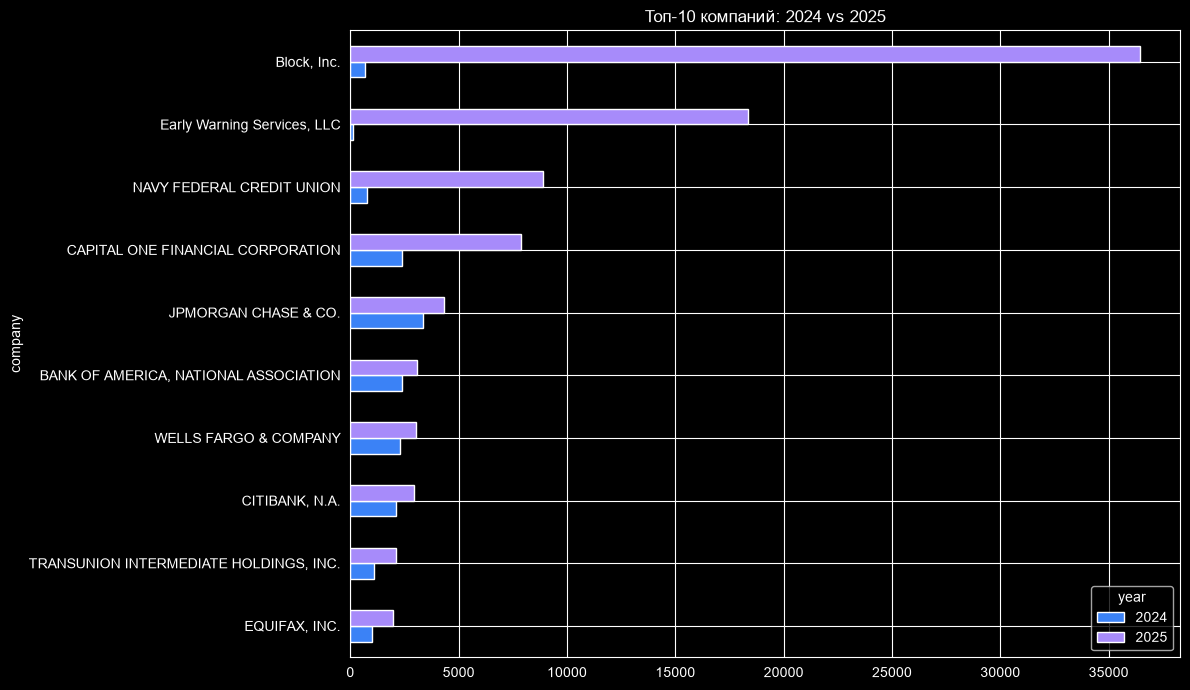

In [63]:
pivot_df = (
    company_counts
    .pivot_table(index="company", columns="year", values="total_complaint", fill_value=0)
    .nlargest(10, 2025)
    .sort_values(2025)
)
pivot_df.plot(kind="barh", figsize=(12, 7), color=["#3B82F6", "#A78BFA"])
plt.title("Топ-10 компаний: 2024 vs 2025")
plt.tight_layout()
plt.show()


#### Как распределено время передачи жалобы компании?

Показатель `hours_to_send` отражает фактическое количество часов между
получением жалобы CFPB и её передачей компании.

Для описания типичного времени используются медиана и 75-й процентиль.
90-й и 99-й процентили позволяют исследовать редкие длительные задержки.

Дополнительно жалобы распределяются по временным интервалам, после чего
сравниваются доли этих интервалов в первом квартале 2024 и 2025 годов.

Показатель характеризует скорость передачи жалобы ведомством CFPB,
а не скорость ответа самой компании.

In [76]:
transfer_data = df.loc[
    df["hours_to_send"].notna()
    & (df["hours_to_send"]>=0)
]
transfer_distribution = (
    transfer_data.groupby(["year", "product"], as_index=False)
    .agg(
        complaint_count=("hours_to_send", "size"),
        mean_hours=("hours_to_send", "mean"),
        median_hours=("hours_to_send", lambda x: x.median()),
        p75_hours=("hours_to_send", lambda x: x.quantile(0.75)),
        p90_hours=("hours_to_send", lambda x: x.quantile(0.90)),
        p99_hours=("hours_to_send", lambda x: x.quantile(0.99)),
        over_24_hours_percent=("hours_to_send", lambda x: x.gt(24).mean()*100)
    ).round(2)
)
transfer_distribution

,year,product,complaint_count,mean_hours,median_hours,p75_hours,p90_hours,p99_hours,over_24_hours_percent
0,2024,Checking or savings account,12122,14.49,0.37,0.75,22.53,265.75,9.46
1,2024,Credit card,16318,13.02,0.27,0.56,2.96,215.23,7.84
2,2024,"Money transfer, virtual currency, or money ser...",4049,20.67,0.34,0.62,1.77,348.29,7.83
3,2025,Checking or savings account,28889,18.01,0.24,0.44,1.27,505.02,6.50
4,2025,Credit card,21541,33.85,0.23,0.54,40.17,887.29,10.63
5,2025,"Money transfer, virtual currency, or money ser...",58903,11.25,0.26,0.46,27.54,181.20,10.84


In [78]:
product_order=(transfer_distribution
    .loc[transfer_distribution ["year"]== 2025]
    .sort_values(
        "over_24_hours_percent",
        ascending=False
    )["product"].tolist())

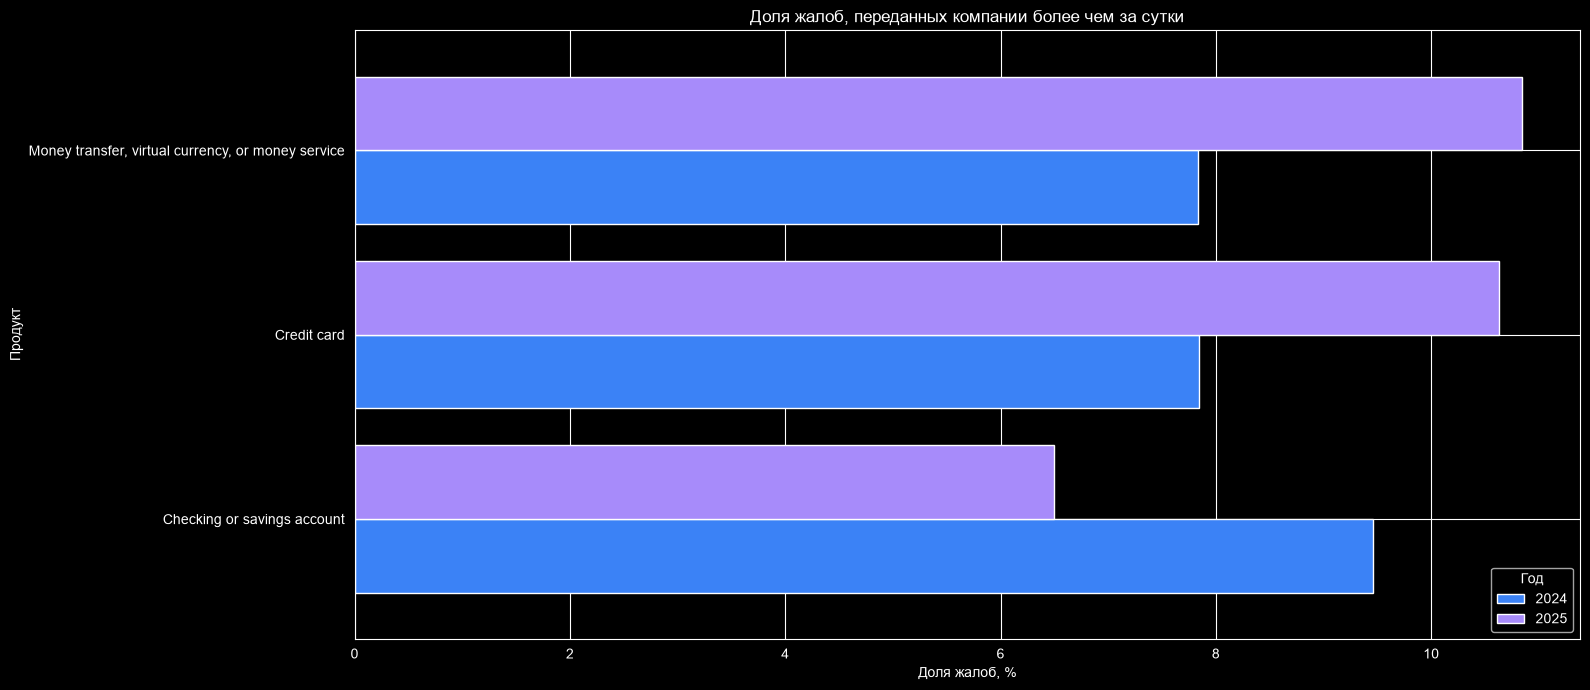

In [94]:
pivot_df = (
    transfer_distribution.pivot_table(
        index="product",
        columns="year",
        values="over_24_hours_percent",
        fill_value=0
    )
)
ax = pivot_df.plot(
    kind="barh",
    figsize=(16, 7),
    color=["#3B82F6", "#A78BFA"],
    width=0.8
)
ax.set_title("Доля жалоб, переданных компании более чем за сутки")
ax.set_xlabel("Доля жалоб, %")
ax.set_ylabel("Продукт")
ax.legend(title="Год")
plt.tight_layout()
plt.show()

#### Чем объясняется необычный объём жалоб в январе 2025 года?